In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow import keras
from tensorflow.keras import layers

In [2]:
df = pd.read_csv("ECG/ecg.csv")

print(df.head())
print(df.shape)
print(df.columns)

   -0.11252183  -2.8272038  -3.7738969  -4.3497511  -4.376041  -3.4749863  \
0    -1.100878   -3.996840   -4.285843   -4.506579  -4.022377   -3.234368   
1    -0.567088   -2.593450   -3.874230   -4.584095  -4.187449   -3.151462   
2     0.490473   -1.914407   -3.616364   -4.318823  -4.268016   -3.881110   
3     0.800232   -0.874252   -2.384761   -3.973292  -4.338224   -3.802422   
4    -1.507674   -3.574550   -4.478011   -4.408275  -3.321242   -2.105171   

   -2.1814082  -1.8182865  -1.2505219  -0.47749208  ...  0.79216787  \
0   -1.566126   -0.992258   -0.754680     0.042321  ...    0.538356   
1   -1.742940   -1.490659   -1.183580    -0.394229  ...    0.886073   
2   -2.993280   -1.671131   -1.333884    -0.965629  ...    0.350816   
3   -2.534510   -1.783423   -1.594450    -0.753199  ...    1.148884   
4   -1.481048   -1.301362   -0.498240    -0.286928  ...    1.089068   

   0.93354122  0.79695779  0.57862066  0.2577399  0.22807718  0.12343082  \
0    0.656881    0.787490    0.724

In [3]:
print(df.info())
print(df.isnull().sum())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Columns: 141 entries, -0.11252183 to 1.0
dtypes: float64(141)
memory usage: 5.4 MB
None
-0.11252183    0
-2.8272038     0
-3.7738969     0
-4.3497511     0
-4.376041      0
              ..
0.22807718     0
0.12343082     0
0.92528624     0
0.19313742     0
1.0            0
Length: 141, dtype: int64
       -0.11252183   -2.8272038   -3.7738969   -4.3497511    -4.376041  \
count  4997.000000  4997.000000  4997.000000  4997.000000  4997.000000   
mean     -0.262532    -1.649593    -2.492366    -3.119508    -3.167414   
std       1.152563     1.445591     1.386477     1.302936     1.104513   
min      -6.729499    -7.090374    -5.132459    -5.363241    -5.375715   
25%      -1.004439    -2.701395    -3.667851    -4.227203    -4.007389   
50%      -0.297583    -1.661891    -2.585872    -3.388020    -3.468898   
75%       0.500057    -0.677702    -1.514058    -2.235425    -2.531019   
max       4.966414     3.479689  

In [4]:
df = pd.read_csv("ECG/ecg.csv", header=None)

print(df.head())
print(df.shape)

        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138       139  140  
0  0.2577

In [5]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print(X.shape)
print(y.value_counts())

(4998, 140)
140
1.0    2919
0.0    2079
Name: count, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
X_train_normal = X_train[y_train == 0]

In [9]:
input_dim = X_train_normal.shape[1]

model = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(input_dim, activation="linear")
])


In [10]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [11]:
history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 1.3098 - mae: 0.8729 - val_loss: 1.2350 - val_mae: 0.8367
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 1.1664 - mae: 0.8154 - val_loss: 1.1238 - val_mae: 0.7885
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1.0405 - mae: 0.7570 - val_loss: 0.9644 - val_mae: 0.7067
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.8782 - mae: 0.6668 - val_loss: 0.8033 - val_mae: 0.6126
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.7411 - mae: 0.5913 - val_loss: 0.6803 - val_mae: 0.5471
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.6266 - mae: 0.5301 - val_loss: 0.5834 - val_mae: 0.4941
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.5434 - mae: 0.4845 - val_loss: 0.5120 - val_mae: 0.4551
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.4812 - mae: 0.4489 - val_loss: 0.4558 - val_mae: 0.4249
Epoch 9/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.4296 - mae: 0.4193 - 

In [14]:
reconstructions = model.predict(X_train_normal, verbose=2)

train_errors = np.mean(
    np.square(X_train_normal - reconstructions),
    axis=1
)

52/52 - 0s - 4ms/step


In [15]:
threshold = np.percentile(train_errors, 99)

print("Anomaly Detection Threshold:", threshold)

Anomaly Detection Threshold: 2.709295889518568


In [16]:
test_reconstructions = model.predict(X_test, verbose=0)

test_errors = np.mean(
    np.square(X_test - test_reconstructions),
    axis=1
)

y_pred = (test_errors > threshold).astype(int)

In [17]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[411   5]
 [584   0]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.41      0.99      0.58       416
         1.0       0.00      0.00      0.00       584

    accuracy                           0.41      1000
   macro avg       0.21      0.49      0.29      1000
weighted avg       0.17      0.41      0.24      1000



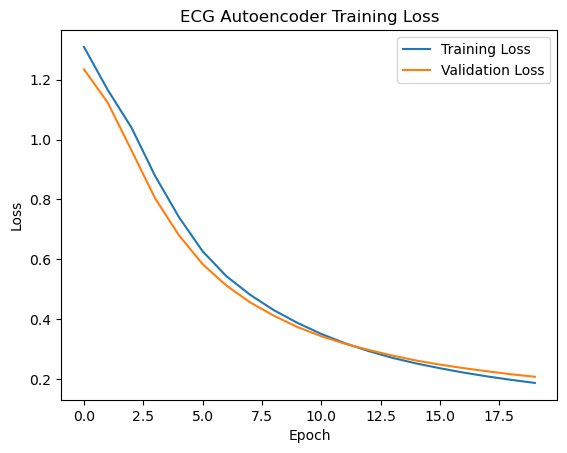

In [18]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ECG Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()